# 파이썬 머신러닝 완벽가이드 — 7장 군집화

ESAA YB · ch7.1~7.7 개념 필사

- **7.1** K-평균 알고리즘 이해
- **7.2** 군집 평가 (실루엣 분석)
- **7.3** 평균 이동
- **7.4** GMM (Gaussian Mixture Model)
- **7.5** DBSCAN
- **7.6** 군집화 실습 — 고객 세그먼테이션
- **7.7** 정리

출처: 저자 깃허브 [wikibook/pymldg-rev](https://github.com/wikibook/pymldg-rev) 7장

6장 차원 축소에 이어 **두 번째 비지도 학습**이다. 6장이 "변수를 줄이는" 일이었다면
7장은 **"행을 묶는"** 일이다. 둘 다 정답(`y`) 없이 데이터의 구조만 보고 한다.


## 데이터 준비

7.1~7.5는 붓꽃과 사이킷런이 만들어 주는 가짜 데이터라 받을 것이 없다.
7.6 실습만 저자 코드가 `Online Retail.xlsx`를 읽는데, 깃허브에 파일이 없어서
**UCI 원본에서 같은 파일을 받아 같은 이름으로 저장한다.**

| 실습 | 저자 파일 | 출처 |
|---|---|---|
| 7.6 고객 세그먼테이션 | `Online Retail.xlsx` (541,909행 × 8열) | UCI [Online Retail](https://archive.ics.uci.edu/dataset/352/online+retail) |

영국 온라인 소매점의 2010-12-01 ~ 2011-12-09 거래 내역이다. 행·열 수가 책과 일치한다.


In [1]:
import io
import os
import zipfile
import urllib.request
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib as mpl

warnings.filterwarnings('ignore')

# 한글 글꼴 (그래프 제목은 영어라 없어도 되지만 맞춰 둔다)
import matplotlib.font_manager as fm
_have = {f.name for f in fm.fontManager.ttflist}
for _f in ('Malgun Gothic', 'NanumGothic', 'AppleGothic', 'Gulim'):
    if _f in _have:
        mpl.rcParams['font.family'] = _f
        break
mpl.rcParams['axes.unicode_minus'] = False

# 저자 코드가 읽는 'Online Retail.xlsx' 를 UCI 원본에서 받아 같은 이름으로 저장
if not os.path.exists('Online Retail.xlsx'):
    _raw = urllib.request.urlopen(
        'https://archive.ics.uci.edu/static/public/352/online+retail.zip', timeout=180).read()
    with zipfile.ZipFile(io.BytesIO(_raw)) as z:
        with open('Online Retail.xlsx', 'wb') as f:
            f.write(z.read('Online Retail.xlsx'))
print('Online Retail.xlsx 준비 완료 ({:,} bytes)'.format(os.path.getsize('Online Retail.xlsx')))


Online Retail.xlsx 준비 완료 (23,715,344 bytes)


## 7.1 K-평균 알고리즘 이해

**K-평균은 군집의 중심점을 옮겨 가며 묶는다.** 순서는 이렇다.

1. 중심점 `K`개를 아무 데나 놓는다
2. 각 점을 **가장 가까운 중심점**에 배정한다
3. 배정된 점들의 **평균**으로 중심점을 옮긴다
4. 중심점이 더 안 움직일 때까지 2~3을 반복한다

쉽고 빠르지만 조건이 붙는다. **군집 개수 `K`를 미리 정해야 하고**, 거리로 묶으니
**군집이 둥글다고 가정**한다. 이 두 가지가 7.3~7.5에서 다른 알고리즘이 나오는 이유다.


In [2]:
from sklearn.preprocessing import scale
from sklearn.datasets import load_iris
from sklearn.cluster import KMeans
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
%matplotlib inline

iris = load_iris()
# 보다 편리한 데이터 Handling을 위해 DataFrame으로 변환
irisDF = pd.DataFrame(data=iris.data, columns=['sepal_length','sepal_width','petal_length','petal_width'])
irisDF.head(3)


,sepal_length,sepal_width,petal_length,petal_width
0,5.1,3.5,1.4,0.2
1,4.9,3.0,1.4,0.2
2,4.7,3.2,1.3,0.2


In [3]:
# 개정판 소스 코드 수정(2019.12.24)
kmeans = KMeans(n_clusters=3, init='k-means++', max_iter=300,random_state=0)
kmeans.fit(irisDF)


KMeans(n_clusters=3, random_state=0)

In [4]:
print(kmeans.labels_)


[1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1
 1 1 1 1 1 1 1 1 1 1 1 1 1 2 0 2 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0
 0 0 0 2 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 2 0 2 2 2 2 0 2 2 2 2
 2 2 0 0 2 2 2 2 0 2 0 2 0 2 2 0 0 2 2 2 2 2 0 2 2 2 2 0 2 2 2 0 2 2 2 0 2
 2 0]


`labels_`에 0·1·2가 들어 있다. **이 숫자는 품종 번호가 아니다.** 군집에 붙은 이름일 뿐이고,
0번 군집이 setosa라는 보장이 없다. 분류의 예측값과 생긴 것은 같지만 의미가 다르다.


In [5]:
# irisDF['cluster']=kmeans.labels_ 개정 소스코드 변경(2019.12.24)

irisDF['target'] = iris.target
irisDF['cluster']=kmeans.labels_
iris_result = irisDF.groupby(['target','cluster'])['sepal_length'].count()
print(iris_result)


target  cluster
0       1          50
1       0          47
        2           3
2       0          14
        2          36
Name: sepal_length, dtype: int64


**정답과 비교해 보면 잘 묶였다.** setosa(target 0)는 50개가 전부 한 군집으로 갔고,
versicolor(1)는 47:3, virginica(2)는 36:14로 갈렸다. 6.2에서 PCA 산점도를 그렸을 때
versicolor와 virginica가 겹쳐 있던 것과 같은 결과다.

**여기서 `target`을 쓴 것은 결과를 확인하려는 것이지 학습에 쓴 게 아니다.**
실제 군집화 문제에는 비교할 정답이 없다. 그래서 7.2에서 정답 없이 평가하는 방법이 나온다.


In [6]:
from sklearn.decomposition import PCA

pca = PCA(n_components=2)
pca_transformed = pca.fit_transform(iris.data)

irisDF['pca_x'] = pca_transformed[:,0]
irisDF['pca_y'] = pca_transformed[:,1]
irisDF.head(3)


,sepal_length,sepal_width,petal_length,petal_width,target,cluster,pca_x,pca_y
0,5.1,3.5,1.4,0.2,0,1,-2.684126,0.319397
1,4.9,3.0,1.4,0.2,0,1,-2.714142,-0.177001
2,4.7,3.2,1.3,0.2,0,1,-2.888991,-0.144949


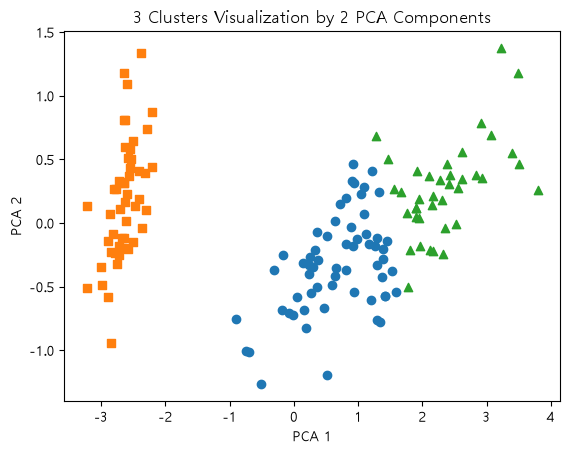

In [7]:
# cluster 값이 0, 1, 2 인 경우마다 별도의 Index로 추출
marker0_ind = irisDF[irisDF['cluster']==0].index
marker1_ind = irisDF[irisDF['cluster']==1].index
marker2_ind = irisDF[irisDF['cluster']==2].index

# cluster값 0, 1, 2에 해당하는 Index로 각 cluster 레벨의 pca_x, pca_y 값 추출. o, s, ^ 로 marker 표시
plt.scatter(x=irisDF.loc[marker0_ind,'pca_x'], y=irisDF.loc[marker0_ind,'pca_y'], marker='o')
plt.scatter(x=irisDF.loc[marker1_ind,'pca_x'], y=irisDF.loc[marker1_ind,'pca_y'], marker='s')
plt.scatter(x=irisDF.loc[marker2_ind,'pca_x'], y=irisDF.loc[marker2_ind,'pca_y'], marker='^')

plt.xlabel('PCA 1')
plt.ylabel('PCA 2')
plt.title('3 Clusters Visualization by 2 PCA Components')
plt.show()


**6장이 여기서 바로 쓰인다.** 붓꽃은 변수가 4개라 그대로는 그릴 수 없으니 PCA로 2차원으로
줄여서 그렸다. 6장에서 "차원 축소의 쓸모 중 하나가 시각화"라고 했던 것이 이것이다.
**군집화 결과는 눈으로 봐야 판단이 되므로, 차원 축소가 거의 항상 따라붙는다.**


### 군집화 테스트용 데이터 만들기

`make_blobs()`는 **중심점 몇 개 주변에 점들을 뿌려** 데이터를 만들어 준다.
정답을 알고 있는 상태에서 알고리즘이 제대로 묶는지 확인할 수 있다.


In [8]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans
from sklearn.datasets import make_blobs
%matplotlib inline

X, y = make_blobs(n_samples=200, n_features=2, centers=3, cluster_std=0.8, random_state=0)
print(X.shape, y.shape)

# y target 값의 분포를 확인
unique, counts = np.unique(y, return_counts=True)
print(unique,counts)


(200, 2) (200,)
[0 1 2] [67 67 66]


In [9]:
import pandas as pd

clusterDF = pd.DataFrame(data=X, columns=['ftr1', 'ftr2'])
clusterDF['target'] = y
clusterDF.head(3)


,ftr1,ftr2,target
0,-1.692427,3.622025,2
1,0.697940,4.428867,0
2,1.100228,4.606317,0


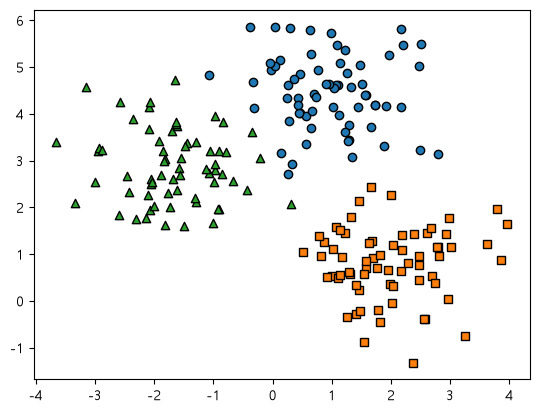

In [10]:
target_list = np.unique(y)
# 각 target별 scatter plot 의 marker 값들.
markers=['o', 's', '^', 'P','D','H','x']
# 3개의 cluster 영역으로 구분한 데이터 셋을 생성했으므로 target_list는 [0,1,2]
# target==0, target==1, target==2 로 scatter plot을 marker별로 생성.
for target in target_list:
    target_cluster = clusterDF[clusterDF['target']==target]
    plt.scatter(x=target_cluster['ftr1'], y=target_cluster['ftr2'], edgecolor='k', marker=markers[target] )
plt.show()


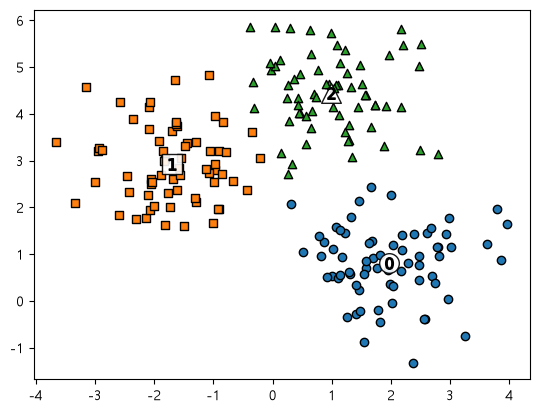

In [11]:
# KMeans 객체를 이용하여 X 데이터를 K-Means 클러스터링 수행
kmeans = KMeans(n_clusters=3, init='k-means++', max_iter=200, random_state=0)
cluster_labels = kmeans.fit_predict(X)
clusterDF['kmeans_label']  = cluster_labels

#cluster_centers_ 는 개별 클러스터의 중심 위치 좌표 시각화를 위해 추출
centers = kmeans.cluster_centers_
unique_labels = np.unique(cluster_labels)
markers=['o', 's', '^', 'P','D','H','x']

# 군집된 label 유형별로 iteration 하면서 marker 별로 scatter plot 수행.
for label in unique_labels:
    label_cluster = clusterDF[clusterDF['kmeans_label']==label]
    center_x_y = centers[label]
    plt.scatter(x=label_cluster['ftr1'], y=label_cluster['ftr2'], edgecolor='k',
                marker=markers[label] )

    # 군집별 중심 위치 좌표 시각화
    plt.scatter(x=center_x_y[0], y=center_x_y[1], s=200, color='white',
                alpha=0.9, edgecolor='k', marker=markers[label])
    plt.scatter(x=center_x_y[0], y=center_x_y[1], s=70, color='k', edgecolor='k',
                marker='$%d$' % label)

plt.show()


In [12]:
print(clusterDF.groupby('target')['kmeans_label'].value_counts())


target  kmeans_label
0       2               66
        1                1
1       0               67
2       1               65
        0                1
Name: count, dtype: int64


**거의 완벽하게 묶인다.** 이 데이터가 K-평균이 가정하는 모양 — 둥글고 크기가 비슷한 덩어리 —
그대로이기 때문이다. 7.4와 7.5에서 이 가정을 깨는 데이터를 만들어 K-평균이 어떻게 무너지는지 본다.


## 7.2 군집 평가 — 실루엣 분석

정답이 없으면 무엇으로 잘됐는지 판단하는가. **실루엣 계수**를 쓴다.

점 하나에 대해 두 거리를 잰다. `a` = 같은 군집 안 다른 점들까지의 평균 거리,
`b` = 가장 가까운 **다른** 군집의 점들까지의 평균 거리.

$$s = \frac{b - a}{\max(a, b)}$$

- `s`가 **1에 가까우면** 제 군집 안에 잘 들어앉아 있다
- `s`가 **0에 가까우면** 군집 경계에 걸쳐 있다
- `s`가 **음수면** 다른 군집에 더 가깝다 — 잘못 묶였다는 뜻


In [13]:
from sklearn.preprocessing import scale
from sklearn.datasets import load_iris
from sklearn.cluster import KMeans
# 실루엣 분석 metric 값을 구하기 위한 API 추가
from sklearn.metrics import silhouette_samples, silhouette_score
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

%matplotlib inline

iris = load_iris()
feature_names = ['sepal_length','sepal_width','petal_length','petal_width']
irisDF = pd.DataFrame(data=iris.data, columns=feature_names)
kmeans = KMeans(n_clusters=3, init='k-means++', max_iter=300,random_state=0).fit(irisDF)

irisDF['cluster'] = kmeans.labels_

# iris 의 모든 개별 데이터에 실루엣 계수값을 구함.
score_samples = silhouette_samples(iris.data, irisDF['cluster'])
print('silhouette_samples( ) return 값의 shape' , score_samples.shape)

# irisDF에 실루엣 계수 컬럼 추가
irisDF['silhouette_coeff'] = score_samples

# 모든 데이터의 평균 실루엣 계수값을 구함.
average_score = silhouette_score(iris.data, irisDF['cluster'])
print('붓꽃 데이터셋 Silhouette Analysis Score:{0:.3f}'.format(average_score))

irisDF.head(3)


silhouette_samples( ) return 값의 shape (150,)
붓꽃 데이터셋 Silhouette Analysis Score:0.551


,sepal_length,sepal_width,petal_length,petal_width,cluster,silhouette_coeff
0,5.1,3.5,1.4,0.2,1,0.852582
1,4.9,3.0,1.4,0.2,1,0.814916
2,4.7,3.2,1.3,0.2,1,0.828797


In [14]:
irisDF.groupby('cluster')['silhouette_coeff'].mean()


cluster
0    0.422323
1    0.797604
2    0.436842
Name: silhouette_coeff, dtype: float64

전체 평균은 0.551인데 **군집별로 보면 0.42 ~ 0.80으로 벌어져 있다.**
한 군집(setosa)은 아주 잘 떨어져 있고 나머지 둘은 서로 붙어 있다는 뜻이다.

**평균만 보면 이 차이가 안 보인다.** 그래서 다음처럼 군집별로 그려 봐야 한다.


### 클러스터별 평균 실루엣 계수의 시각화를 통한 클러스터 개수 최적화 방법


In [15]:
### 여러개의 클러스터링 갯수를 List로 입력 받아 각각의 실루엣 계수를 면적으로 시각화한 함수 작성
def visualize_silhouette(cluster_lists, X_features):

    from sklearn.datasets import make_blobs
    from sklearn.cluster import KMeans
    from sklearn.metrics import silhouette_samples, silhouette_score

    import matplotlib.pyplot as plt
    import matplotlib.cm as cm
    import math

    # 입력값으로 클러스터링 갯수들을 리스트로 받아서, 각 갯수별로 클러스터링을 적용하고 실루엣 개수를 구함
    n_cols = len(cluster_lists)

    # plt.subplots()으로 리스트에 기재된 클러스터링 수만큼의 sub figures를 가지는 axs 생성
    fig, axs = plt.subplots(figsize=(4*n_cols, 4), nrows=1, ncols=n_cols)

    # 리스트에 기재된 클러스터링 갯수들을 차례로 iteration 수행하면서 실루엣 개수 시각화
    for ind, n_cluster in enumerate(cluster_lists):

        # KMeans 클러스터링 수행하고, 실루엣 스코어와 개별 데이터의 실루엣 값 계산.
        clusterer = KMeans(n_clusters = n_cluster, max_iter=500, random_state=0)
        cluster_labels = clusterer.fit_predict(X_features)

        sil_avg = silhouette_score(X_features, cluster_labels)
        sil_values = silhouette_samples(X_features, cluster_labels)

        y_lower = 10
        axs[ind].set_title('Number of Cluster : '+ str(n_cluster)+'\n' \
                          'Silhouette Score :' + str(round(sil_avg,3)) )
        axs[ind].set_xlabel("The silhouette coefficient values")
        axs[ind].set_ylabel("Cluster label")
        axs[ind].set_xlim([-0.1, 1])
        axs[ind].set_ylim([0, len(X_features) + (n_cluster + 1) * 10])
        axs[ind].set_yticks([])  # Clear the yaxis labels / ticks
        axs[ind].set_xticks([0, 0.2, 0.4, 0.6, 0.8, 1])

        # 클러스터링 갯수별로 fill_betweenx( )형태의 막대 그래프 표현.
        for i in range(n_cluster):
            ith_cluster_sil_values = sil_values[cluster_labels==i]
            ith_cluster_sil_values.sort()

            size_cluster_i = ith_cluster_sil_values.shape[0]
            y_upper = y_lower + size_cluster_i

            color = cm.nipy_spectral(float(i) / n_cluster)
            axs[ind].fill_betweenx(np.arange(y_lower, y_upper), 0, ith_cluster_sil_values, \
                                facecolor=color, edgecolor=color, alpha=0.7)
            axs[ind].text(-0.05, y_lower + 0.5 * size_cluster_i, str(i))
            y_lower = y_upper + 10

        axs[ind].axvline(x=sil_avg, color="red", linestyle="--")


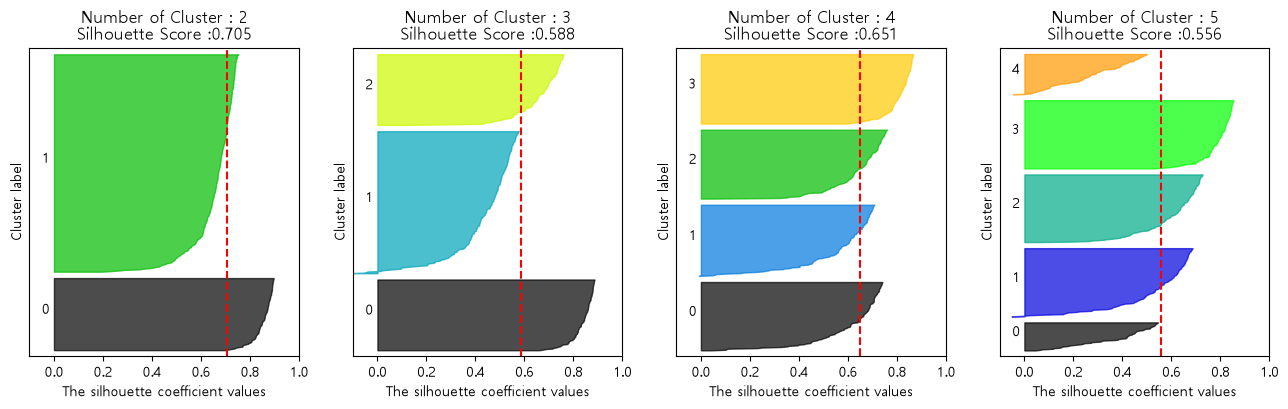

In [16]:
# make_blobs 을 통해 clustering 을 위한 4개의 클러스터 중심의 500개 2차원 데이터 셋 생성
from sklearn.datasets import make_blobs
X, y = make_blobs(n_samples=500, n_features=2, centers=4, cluster_std=1, \
                  center_box=(-10.0, 10.0), shuffle=True, random_state=1)

# cluster 개수를 2개, 3개, 4개, 5개 일때의 클러스터별 실루엣 계수 평균값을 시각화
visualize_silhouette([ 2, 3, 4, 5], X)


**이 그림을 읽는 법이 중요하다.** 빨간 점선이 전체 평균이고, 가로 막대 하나가 군집 하나다.

군집 2개일 때 평균 점수가 0.704로 제일 높지만, **군집 하나가 다른 하나보다 훨씬 크다.**
군집 4개일 때는 평균이 0.651로 조금 낮아도 **네 덩어리의 크기와 점수가 고르다.**
실제로 이 데이터는 `centers=4`로 만든 것이니 4가 정답이다.

**평균 점수가 가장 높은 K가 정답이 아니다.** 군집들이 고르게 나뉘었는지를 같이 봐야 한다.
5장에서 "정확도가 높아도 불균형 데이터면 의미가 없다"고 했던 것과 같은 종류의 함정이다.


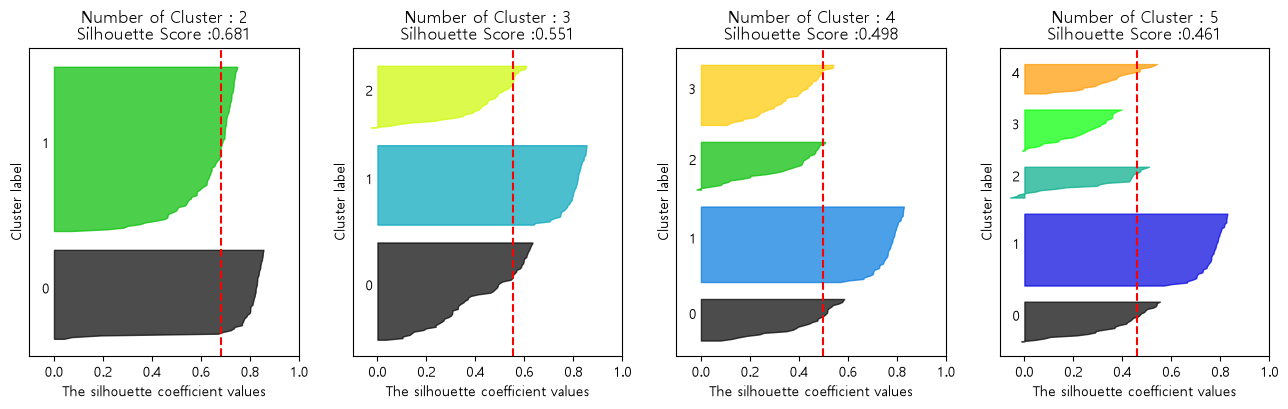

In [17]:
from sklearn.datasets import load_iris

iris=load_iris()
visualize_silhouette([ 2, 3, 4,5 ], iris.data)


붓꽃은 **군집 2개일 때 평균이 가장 높다.** 품종이 3개라는 걸 아는 입장에서는 이상해 보이지만,
versicolor와 virginica가 서로 붙어 있어서 **데이터만 보면 두 덩어리로 보이는 것이 맞다.**
정답을 모르는 상태에서 실루엣만으로 3을 고를 수는 없다는 뜻이다. 군집 평가의 한계다.


## 7.3 평균 이동 (Mean Shift)

K-평균이 **평균**으로 중심을 옮겼다면, 평균 이동은 **데이터가 가장 빽빽한 쪽**으로 중심을 옮긴다.
확률 밀도가 높은 방향을 찾아 올라가다가 더 올라갈 곳이 없으면 거기가 중심이 된다.

**가장 큰 차이는 군집 개수를 지정하지 않는다는 것이다.** 대신 `bandwidth`(탐색 반경)를 정해야 하고,
이 값이 군집 개수를 좌우한다.


In [18]:
import numpy as np
from sklearn.datasets import make_blobs
from sklearn.cluster import MeanShift

X, y = make_blobs(n_samples=200, n_features=2, centers=3,
                  cluster_std=0.7, random_state=0)

meanshift= MeanShift(bandwidth=0.8)
cluster_labels = meanshift.fit_predict(X)
print('cluster labels 유형:', np.unique(cluster_labels))


cluster labels 유형: [0 1 2 3 4 5]


In [19]:
meanshift= MeanShift(bandwidth=1)
cluster_labels = meanshift.fit_predict(X)
print('cluster labels 유형:', np.unique(cluster_labels))


cluster labels 유형: [0 1 2]


**`bandwidth`를 0.8에서 1로 바꿨을 뿐인데 군집이 6개에서 3개로 줄었다.**
반경이 좁으면 작은 봉우리까지 따로 세고, 넓으면 뭉뚱그린다.
군집 개수를 안 정해도 되는 대신 이 값에 결과가 통째로 달려 있다.


In [20]:
from sklearn.cluster import estimate_bandwidth

bandwidth = estimate_bandwidth(X)
print('bandwidth 값:', round(bandwidth,3))


bandwidth 값: 1.816


In [21]:
import pandas as pd


clusterDF = pd.DataFrame(data=X, columns=['ftr1', 'ftr2'])
clusterDF['target'] = y

# estimate_bandwidth()로 최적의 bandwidth 계산
best_bandwidth = estimate_bandwidth(X)

meanshift= MeanShift(bandwidth=best_bandwidth)
cluster_labels = meanshift.fit_predict(X)
print('cluster labels 유형:',np.unique(cluster_labels))


cluster labels 유형: [0 1 2]


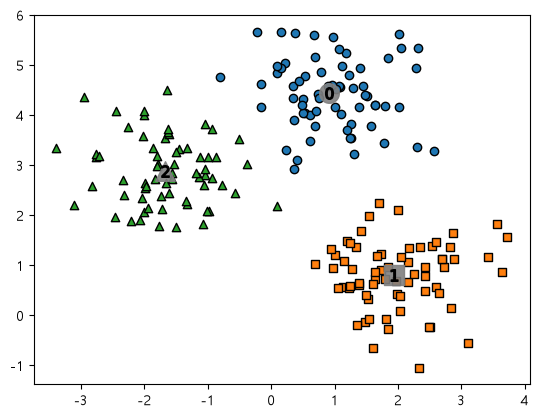

In [22]:
import matplotlib.pyplot as plt
%matplotlib inline

clusterDF['meanshift_label']  = cluster_labels
centers = meanshift.cluster_centers_
unique_labels = np.unique(cluster_labels)
markers=['o', 's', '^', 'x', '*']

for label in unique_labels:
    label_cluster = clusterDF[clusterDF['meanshift_label']==label]
    center_x_y = centers[label]
    # 군집별로 다른 마커로 산점도 적용
    plt.scatter(x=label_cluster['ftr1'], y=label_cluster['ftr2'], edgecolor='k', marker=markers[label] )

    # 군집별 중심 표현
    plt.scatter(x=center_x_y[0], y=center_x_y[1], s=200, color='gray', alpha=0.9, marker=markers[label])
    plt.scatter(x=center_x_y[0], y=center_x_y[1], s=70, color='k', edgecolor='k', marker='$%d$' % label)

plt.show()


In [23]:
print(clusterDF.groupby('target')['meanshift_label'].value_counts())


target  meanshift_label
0       0                  67
1       1                  67
2       2                  66
Name: count, dtype: int64


`estimate_bandwidth()`가 찾아 준 값으로 돌리니 군집 3개가 정확히 나온다.
**다만 평균 이동은 느리다.** 점마다 밀도를 계산하며 이동시켜야 해서, 데이터가 커지면 쓰기 어렵다.
책에서도 업무용 정형 데이터보다 **영상 처리의 객체 추적** 쪽에서 쓰인다고 적혀 있다.


## 7.4 GMM (Gaussian Mixture Model)

발상이 다르다. **"데이터가 여러 개의 정규분포가 섞여서 만들어졌다"고 보고,
그 정규분포들을 역으로 찾아낸다.** 그리고 각 점이 어느 분포에서 나왔을 확률이 가장 높은지로 묶는다.

K-평균이 **거리**를 쓰고 GMM이 **분포**를 쓴다는 차이가 결과를 가른다.
거리로 묶으면 군집이 원이 되지만, 정규분포는 **길쭉한 타원**도 될 수 있다.


In [24]:
from sklearn.datasets import load_iris
from sklearn.cluster import KMeans

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
%matplotlib inline

iris = load_iris()
feature_names = ['sepal_length','sepal_width','petal_length','petal_width']

# 보다 편리한 데이타 Handling을 위해 DataFrame으로 변환
irisDF = pd.DataFrame(data=iris.data, columns=feature_names)
irisDF['target'] = iris.target


In [25]:
from sklearn.mixture import GaussianMixture

gmm = GaussianMixture(n_components=3, random_state=0).fit(iris.data)
gmm_cluster_labels = gmm.predict(iris.data)

# 클러스터링 결과를 irisDF 의 'gmm_cluster' 컬럼명으로 저장
irisDF['gmm_cluster'] = gmm_cluster_labels
irisDF['target'] = iris.target

# target 값에 따라서 gmm_cluster 값이 어떻게 매핑되었는지 확인.
iris_result = irisDF.groupby(['target'])['gmm_cluster'].value_counts()
print(iris_result)


target  gmm_cluster
0       1              50
1       0              45
        2               5
2       2              50
Name: count, dtype: int64

In [26]:
kmeans = KMeans(n_clusters=3, init='k-means++', max_iter=300,random_state=0).fit(iris.data)
kmeans_cluster_labels = kmeans.predict(iris.data)
irisDF['kmeans_cluster'] = kmeans_cluster_labels
iris_result = irisDF.groupby(['target'])['kmeans_cluster'].value_counts()
print(iris_result)


target  kmeans_cluster
0       1                 50
1       0                 47
        2                  3
2       2                 36
        0                 14
Name: count, dtype: int64


**붓꽃에서는 GMM이 더 잘 묶었다.** GMM은 어긋난 것이 5건(versicolor 5개)뿐인데,
K-평균은 17건(versicolor 3개 + virginica 14개)이 다른 군집으로 갔다.
그런데 책은 여기서 **"GMM이 항상 낫다는 뜻은 아니다"**라고 못을 박는다.
데이터의 모양에 따라 다르고, 붓꽃이 마침 GMM에 맞는 모양이었을 뿐이다.

다음 셀부터가 **모양의 차이를 눈으로 보여 주는 부분**이다.


In [27]:
### 클러스터 결과를 담은 DataFrame과 사이킷런의 Cluster 객체등을 인자로 받아 클러스터링 결과를 시각화하는 함수
def visualize_cluster_plot(clusterobj, dataframe, label_name, iscenter=True):
    if iscenter :
        centers = clusterobj.cluster_centers_

    unique_labels = np.unique(dataframe[label_name].values)
    markers=['o', 's', '^', 'x', '*']
    isNoise=False

    for label in unique_labels:
        label_cluster = dataframe[dataframe[label_name]==label]
        if label == -1:
            cluster_legend = 'Noise'
            isNoise=True
        else :
            cluster_legend = 'Cluster '+str(label)

        plt.scatter(x=label_cluster['ftr1'], y=label_cluster['ftr2'], s=70,\
                    edgecolor='k', marker=markers[label], label=cluster_legend)

        if iscenter:
            center_x_y = centers[label]
            plt.scatter(x=center_x_y[0], y=center_x_y[1], s=250, color='white',
                        alpha=0.9, edgecolor='k', marker=markers[label])
            plt.scatter(x=center_x_y[0], y=center_x_y[1], s=70, color='k',\
                        edgecolor='k', marker='$%d$' % label)
    if isNoise:
        legend_loc='upper center'
    else: legend_loc='upper right'

    plt.legend(loc=legend_loc)
    plt.show()


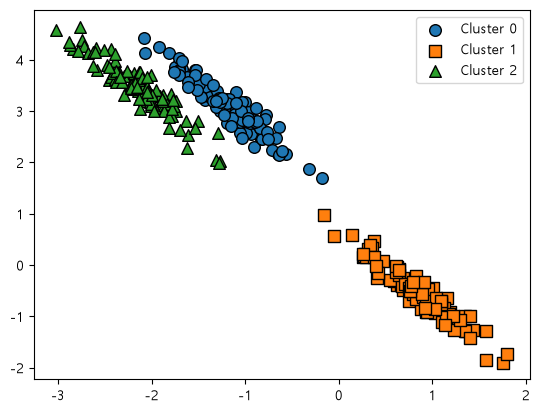

In [28]:
from sklearn.datasets import make_blobs

# make_blobs() 로 300개의 데이터 셋, 3개의 cluster 셋, cluster_std=0.5 을 만듬.
X, y = make_blobs(n_samples=300, n_features=2, centers=3, cluster_std=0.5, random_state=0)

# 길게 늘어난 타원형의 데이터 셋을 생성하기 위해 변환함.
transformation = [[0.60834549, -0.63667341], [-0.40887718, 0.85253229]]
X_aniso = np.dot(X, transformation)
# feature 데이터 셋과 make_blobs( ) 의 y 결과 값을 DataFrame으로 저장
clusterDF = pd.DataFrame(data=X_aniso, columns=['ftr1', 'ftr2'])
clusterDF['target'] = y
# 생성된 데이터 셋을 target 별로 다른 marker 로 표시하여 시각화 함.
visualize_cluster_plot(None, clusterDF, 'target', iscenter=False)


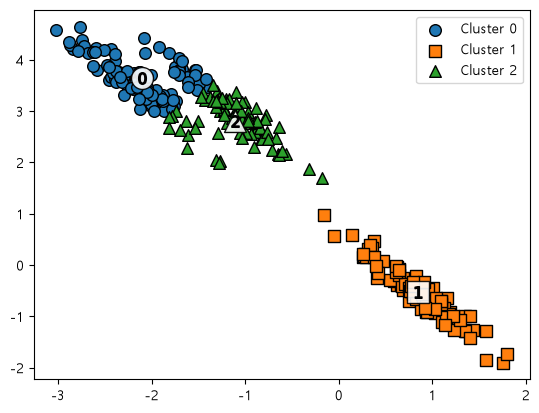

In [29]:
# 3개의 Cluster 기반 Kmeans 를 X_aniso 데이터 셋에 적용
kmeans = KMeans(3, random_state=0)
kmeans_label = kmeans.fit_predict(X_aniso)
clusterDF['kmeans_label'] = kmeans_label

visualize_cluster_plot(kmeans, clusterDF, 'kmeans_label',iscenter=True)


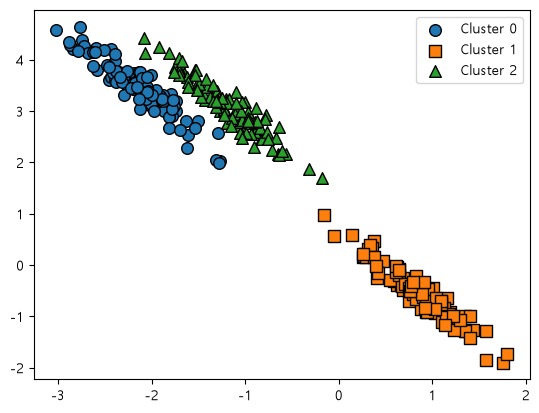

In [30]:
# 3개의 n_components기반 GMM을 X_aniso 데이터 셋에 적용
gmm = GaussianMixture(n_components=3, random_state=0)
gmm_label = gmm.fit(X_aniso).predict(X_aniso)
clusterDF['gmm_label'] = gmm_label

# GaussianMixture는 cluster_centers_ 속성이 없으므로 iscenter를 False로 설정.
visualize_cluster_plot(gmm, clusterDF, 'gmm_label',iscenter=False)


In [31]:
print('### KMeans Clustering ###')
print(clusterDF.groupby('target')['kmeans_label'].value_counts())
print('\n### Gaussian Mixture Clustering ###')
print(clusterDF.groupby('target')['gmm_label'].value_counts())


### KMeans Clustering ###
target  kmeans_label
0       2                73
        0                27
1       1               100
2       0                86
        2                14
Name: count, dtype: int64

### Gaussian Mixture Clustering ###
target  gmm_label
0       2            100
1       1            100
2       0            100
Name: count, dtype: int64


**세 장의 그림을 나란히 보면 차이가 분명하다.** 길쭉하게 늘어뜨린 데이터에서
K-평균은 **원 모양으로 잘라** 세 덩어리를 가로질러 버렸고, GMM은 길쭉한 덩어리를 그대로 잡았다.
숫자로도 GMM이 100:100:100으로 정확하고 K-평균은 섞였다.

**K-평균은 중심에서의 거리로만 판단하니 군집이 원이 될 수밖에 없다.**
이게 K-평균의 구조적 한계이고, GMM이 필요한 이유다.


## 7.5 DBSCAN

또 다른 발상이다. **"점이 빽빽하게 모여 있으면 한 군집"**으로 본다. 두 값을 정한다.

- `eps` — 이웃으로 칠 반경
- `min_samples` — 그 반경 안에 이만큼 있어야 '핵심 점'

핵심 점끼리 이어 붙여 군집을 만들고, **어디에도 못 끼는 점은 노이즈(`-1`)**로 남긴다.

DBSCAN이 가진 것은 둘이다. **군집 개수를 안 정해도 되고, 군집이 원이 아니어도 된다.**
그리고 **노이즈를 따로 빼 준다** — 군집화 알고리즘 중에 이걸 해 주는 게 드물다.


In [32]:
from sklearn.datasets import load_iris

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
%matplotlib inline

iris = load_iris()
feature_names = ['sepal_length','sepal_width','petal_length','petal_width']

# 보다 편리한 데이타 Handling을 위해 DataFrame으로 변환
irisDF = pd.DataFrame(data=iris.data, columns=feature_names)
irisDF['target'] = iris.target


In [33]:
from sklearn.cluster import DBSCAN

dbscan = DBSCAN(eps=0.6, min_samples=8, metric='euclidean')
dbscan_labels = dbscan.fit_predict(iris.data)

irisDF['dbscan_cluster'] = dbscan_labels
irisDF['target'] = iris.target

iris_result = irisDF.groupby(['target'])['dbscan_cluster'].value_counts()
print(iris_result)


target  dbscan_cluster
0        0                49
        -1                 1
1        1                46
        -1                 4
2        1                42
        -1                 8
Name: count, dtype: int64


**군집이 3개가 아니라 2개(0, 1)로 나왔고 노이즈가 몇 개 생겼다.**
7.2의 실루엣 분석에서 붓꽃이 "두 덩어리로 보인다"고 했던 것과 같은 결론이다.
**정답을 모르고 데이터만 보면 붓꽃은 두 군집이다.**


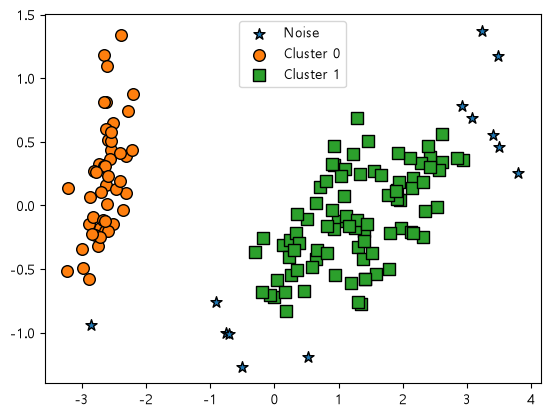

In [34]:
from sklearn.decomposition import PCA
# 2차원으로 시각화하기 위해 PCA n_componets=2로 피처 데이터 세트 변환
pca = PCA(n_components=2, random_state=0)
pca_transformed = pca.fit_transform(iris.data)
# visualize_cluster_plot( ) 함수는 ftr1, ftr2 컬럼을 좌표에 표현하므로 PCA 변환값을 해당 컬럼으로 생성
irisDF['ftr1'] = pca_transformed[:,0]
irisDF['ftr2'] = pca_transformed[:,1]

visualize_cluster_plot(dbscan, irisDF, 'dbscan_cluster', iscenter=False)


target  dbscan_cluster
0        0                50
1        1                50
2        1                47
        -1                 3
Name: count, dtype: int64


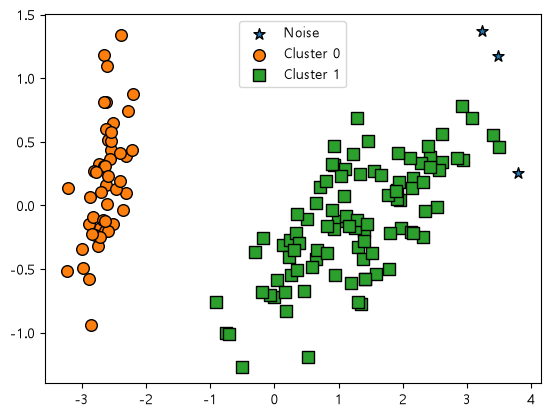

In [35]:
from sklearn.cluster import DBSCAN

dbscan = DBSCAN(eps=0.8, min_samples=8, metric='euclidean')
dbscan_labels = dbscan.fit_predict(iris.data)

irisDF['dbscan_cluster'] = dbscan_labels
irisDF['target'] = iris.target

iris_result = irisDF.groupby(['target'])['dbscan_cluster'].value_counts()
print(iris_result)

visualize_cluster_plot(dbscan, irisDF, 'dbscan_cluster', iscenter=False)


target  dbscan_cluster
0        0                48
        -1                 2
1        1                44
        -1                 6
2        1                36
        -1                14
Name: count, dtype: int64


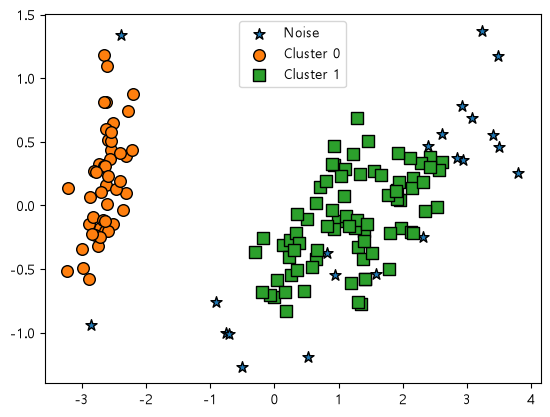

In [36]:
dbscan = DBSCAN(eps=0.6, min_samples=16, metric='euclidean')
dbscan_labels = dbscan.fit_predict(iris.data)

irisDF['dbscan_cluster'] = dbscan_labels
irisDF['target'] = iris.target

iris_result = irisDF.groupby(['target'])['dbscan_cluster'].value_counts()
print(iris_result)
visualize_cluster_plot(dbscan, irisDF, 'dbscan_cluster', iscenter=False)


두 값을 움직여 보면 성격이 보인다.

- `eps`를 0.6 → 0.8로 **넓히면** 이웃이 늘어 노이즈가 줄어든다
- `min_samples`를 8 → 16으로 **올리면** 핵심 점 조건이 빡빡해져 노이즈가 늘어난다

**둘이 반대 방향으로 작동한다.** 평균 이동의 `bandwidth`처럼, 군집 개수를 안 정하는 대신
다른 값을 정해야 하는 건 마찬가지다.


### DBSCAN 적용하기 — make_circles() 데이터 세트

DBSCAN의 진가는 여기서 나온다. **원 안에 원이 들어 있는 데이터**다.


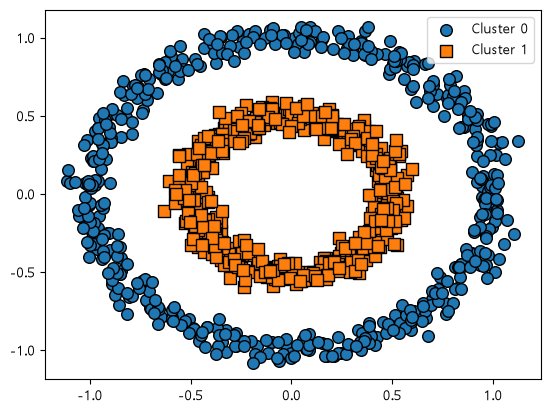

In [37]:
from sklearn.datasets import make_circles

X, y = make_circles(n_samples=1000, shuffle=True, noise=0.05, random_state=0, factor=0.5)
clusterDF = pd.DataFrame(data=X, columns=['ftr1', 'ftr2'])
clusterDF['target'] = y

visualize_cluster_plot(None, clusterDF, 'target', iscenter=False)


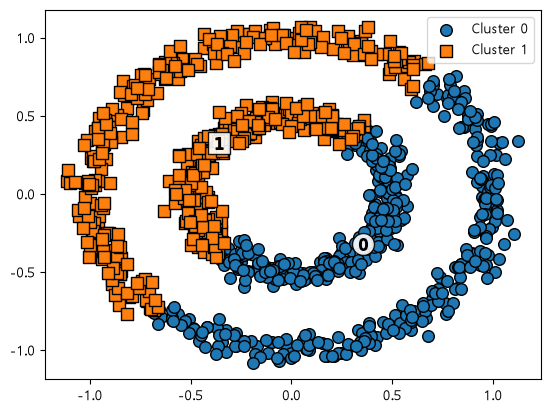

In [38]:
# KMeans로 make_circles( ) 데이터 셋을 클러스터링 수행.
from sklearn.cluster import KMeans

kmeans = KMeans(n_clusters=2, max_iter=1000, random_state=0)
kmeans_labels = kmeans.fit_predict(X)
clusterDF['kmeans_cluster'] = kmeans_labels

visualize_cluster_plot(kmeans, clusterDF, 'kmeans_cluster', iscenter=True)


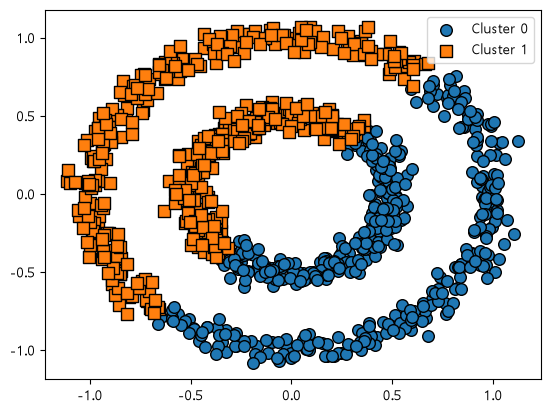

In [39]:
# GMM으로 make_circles( ) 데이터 셋을 클러스터링 수행.
from sklearn.mixture import GaussianMixture

gmm = GaussianMixture(n_components=2, random_state=0)
gmm_label = gmm.fit(X).predict(X)
clusterDF['gmm_cluster'] = gmm_label

visualize_cluster_plot(gmm, clusterDF, 'gmm_cluster', iscenter=False)


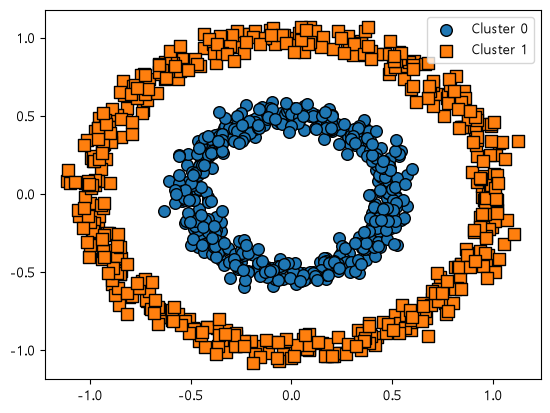

In [40]:
# DBSCAN으로 make_circles( ) 데이터 셋을 클러스터링 수행.
from sklearn.cluster import DBSCAN

dbscan = DBSCAN(eps=0.2, min_samples=10, metric='euclidean')
dbscan_labels = dbscan.fit_predict(X)
clusterDF['dbscan_cluster'] = dbscan_labels

visualize_cluster_plot(dbscan, clusterDF, 'dbscan_cluster', iscenter=False)


**이 세 장이 7장 전체에서 제일 중요한 그림이다.**

- **K-평균**은 위아래로 잘랐다. 중심에서의 거리로만 보니 안쪽 원과 바깥 원을 구분할 방법이 없다.
- **GMM**도 비슷하게 실패했다. 타원은 되지만 **가운데가 빈 고리 모양**은 정규분포로 표현할 수 없다.
- **DBSCAN**만 안쪽 원과 바깥 고리를 정확히 나눴다. 붙어 있는 점들을 따라가며 이어 붙이는 방식이라
  모양에 제약이 없다.

**7.4에서 GMM이 K-평균보다 나았다고 해서 GMM이 더 좋은 알고리즘인 게 아니다.**
데이터 모양마다 맞는 알고리즘이 다르다는 것이 이 세 장의 결론이다.


## 7.6 군집화 실습 — 고객 세그먼테이션

여기부터는 진짜 데이터다. 영국 온라인 소매점의 거래 내역으로 **고객을 몇 개 유형으로 나눈다.**
앞의 예제들과 달리 **정답이 아예 없다.** 군집화를 실제로 쓰는 상황이 이렇다.


In [41]:
import pandas as pd
import datetime
import math
import numpy as np
import matplotlib.pyplot as plt
%matplotlib inline

retail_df = pd.read_excel(io='Online Retail.xlsx')
retail_df.head(3)


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom


In [42]:
retail_df.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 541909 entries, 0 to 541908
Data columns (total 8 columns):
 #   Column       Non-Null Count   Dtype         
---  ------       --------------   -----         
 0   InvoiceNo    541909 non-null  object        
 1   StockCode    541909 non-null  object        
 2   Description  540455 non-null  object        
 3   Quantity     541909 non-null  int64         
 4   InvoiceDate  541909 non-null  datetime64[ns]
 5   UnitPrice    541909 non-null  float64       
 6   CustomerID   406829 non-null  float64       
 7   Country      541909 non-null  object        
dtypes: datetime64[ns](1), float64(2), int64(1), object(4)
memory usage: 33.1+ MB


In [43]:
retail_df = retail_df[retail_df['Quantity'] > 0]
retail_df = retail_df[retail_df['UnitPrice'] > 0]
retail_df = retail_df[retail_df['CustomerID'].notnull()]
print(retail_df.shape)
retail_df.isnull().sum()


(397884, 8)

InvoiceNo      0
StockCode      0
Description    0
Quantity       0
InvoiceDate    0
UnitPrice      0
CustomerID     0
Country        0
dtype: int64

**세 줄의 정리가 각각 다른 이유를 갖는다.**

- `Quantity > 0` — 음수는 **반품**이다. 구매 행동을 보려는 것이니 뺀다
- `UnitPrice > 0` — 가격 0은 사은품이나 오류다
- `CustomerID` 결측 제거 — **고객별로 묶는 게 목적인데 누구인지 모르면 쓸 수 없다**

54만 행이 39만 행으로 줄었다. 결측치를 채우지 않고 지운 것은 **목적이 고객 단위 분석**이기 때문이다.
5장 주택 가격에서 `PoolQC` 결측을 "수영장이 없다"로 읽었던 것과 달리, 여기서는 채울 방법이 없다.


In [44]:
retail_df['Country'].value_counts()[:5]


Country
United Kingdom    354321
Germany             9040
France              8341
EIRE                7236
Spain               2484
Name: count, dtype: int64

In [45]:
retail_df = retail_df[retail_df['Country']=='United Kingdom']
print(retail_df.shape)


(354321, 8)


영국이 전체의 90% 이상이다. **나라마다 구매 패턴이 다를 텐데 섞어서 묶으면
"영국 고객 유형"이 아니라 "나라 구분"이 되어 버린다.** 그래서 영국만 남긴다.


### RFM 기반 데이터 가공

**RFM은 고객을 보는 세 축이다.**

| | 뜻 | 만드는 법 |
|---|---|---|
| **R**ecency | 얼마나 **최근에** 샀나 | 기준일 − 마지막 구매일 |
| **F**requency | 얼마나 **자주** 샀나 | 주문 건수 |
| **M**onetary | 얼마나 **많이** 썼나 | 구매 금액 합계 |

거래 한 줄씩 있는 데이터를 **고객 한 명당 한 줄**로 바꾸는 작업이다.
미니 프로젝트에서 읽은 주차수요 예측 수상작이 "한 단지가 여러 행"을 단지 단위로 합쳤던 것과 같은 구조다.


In [46]:
retail_df['sale_amount'] = retail_df['Quantity'] * retail_df['UnitPrice']
retail_df['CustomerID'] = retail_df['CustomerID'].astype(int)


In [47]:
print(retail_df['CustomerID'].value_counts().head(5))
print(retail_df.groupby('CustomerID')['sale_amount'].sum().sort_values(ascending=False)[:5])


CustomerID
17841    7847
14096    5111
12748    4595
14606    2700
15311    2379
Name: count, dtype: int64
CustomerID
18102    259657.30
17450    194550.79
16446    168472.50
17511     91062.38
16029     81024.84
Name: sale_amount, dtype: float64


In [48]:
retail_df.groupby(['InvoiceNo','StockCode'])['InvoiceNo'].count().mean()


np.float64(1.028702077315023)

In [49]:
# DataFrame의 groupby() 의 multiple 연산을 위해 agg() 이용
# Recency는 InvoiceDate 컬럼의 max() 에서 데이터 가공
# Frequency는 InvoiceNo 컬럼의 count() , Monetary value는 sale_amount 컬럼의 sum()
aggregations = {
    'InvoiceDate': 'max',
    'InvoiceNo': 'count',
    'sale_amount':'sum'
}
cust_df = retail_df.groupby('CustomerID').agg(aggregations)
# groupby된 결과 컬럼값을 Recency, Frequency, Monetary로 변경
cust_df = cust_df.rename(columns = {'InvoiceDate':'Recency',
                                    'InvoiceNo':'Frequency',
                                    'sale_amount':'Monetary'
                                   }
                        )
cust_df = cust_df.reset_index()
cust_df.head(3)


,CustomerID,Recency,Frequency,Monetary
0,12346,2011-01-18 10:01:00,1,77183.60
1,12747,2011-12-07 14:34:00,103,4196.01
2,12748,2011-12-09 12:20:00,4595,33719.73


In [50]:
import datetime as dt

cust_df['Recency'] = dt.datetime(2011,12,10) - cust_df['Recency']
cust_df['Recency'] = cust_df['Recency'].apply(lambda x: x.days+1)
print('cust_df 로우와 컬럼 건수는 ',cust_df.shape)
cust_df.head(3)


cust_df 로우와 컬럼 건수는  (3920, 4)


,CustomerID,Recency,Frequency,Monetary
0,12346,326,1,77183.60
1,12747,3,103,4196.01
2,12748,1,4595,33719.73


39만 행이 **3,920명**으로 줄었다. 기준일을 데이터의 마지막 날(2011-12-09)의 다음 날로 잡고
날짜 차이를 일수로 바꿨다. `+1`을 하는 이유는 **당일 구매한 고객의 Recency를 0이 아니라 1**로 두기 위해서다.


### RFM 기반 고객 세그먼테이션


(array([3.887e+03, 1.900e+01, 9.000e+00, 2.000e+00, 0.000e+00, 0.000e+00,
        1.000e+00, 1.000e+00, 0.000e+00, 1.000e+00]),
 array([3.75000000e+00, 2.59691050e+04, 5.19344600e+04, 7.78998150e+04,
        1.03865170e+05, 1.29830525e+05, 1.55795880e+05, 1.81761235e+05,
        2.07726590e+05, 2.33691945e+05, 2.59657300e+05]),
 <BarContainer object of 10 artists>)

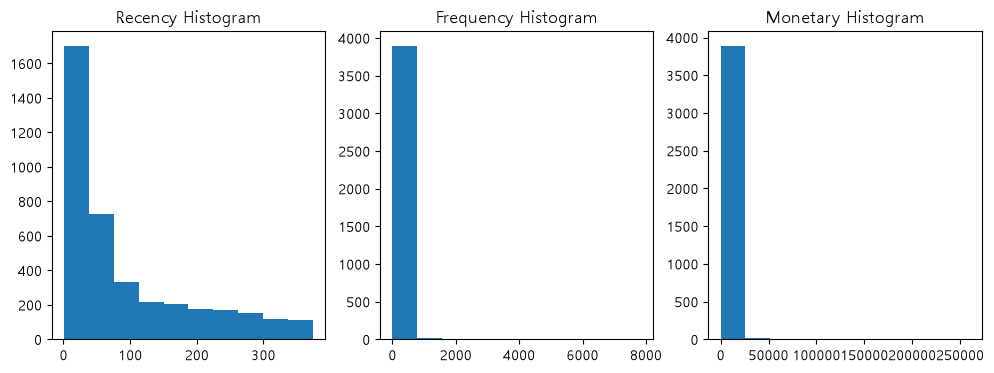

In [51]:
fig, (ax1,ax2,ax3) = plt.subplots(figsize=(12,4), nrows=1, ncols=3)
ax1.set_title('Recency Histogram')
ax1.hist(cust_df['Recency'])

ax2.set_title('Frequency Histogram')
ax2.hist(cust_df['Frequency'])

ax3.set_title('Monetary Histogram')
ax3.hist(cust_df['Monetary'])


In [52]:
cust_df[['Recency','Frequency','Monetary']].describe()


,Recency,Frequency,Monetary
count,3920.000000,3920.000000,3920.000000
mean,92.742092,90.388010,1864.385601
std,99.533485,217.808385,7482.817477
min,1.000000,1.000000,3.750000
25%,18.000000,17.000000,300.280000
50%,51.000000,41.000000,652.280000
75%,143.000000,99.250000,1576.585000
max,374.000000,7847.000000,259657.300000


**세 변수 모두 심하게 치우쳐 있다.** Monetary는 평균 1,864인데 최대가 259,657이고,
Frequency는 평균 90인데 최대가 7,847이다. 소매 데이터의 전형적인 모습 —
**대부분은 한두 번 사고 말지만 소수의 단골이 엄청나게 산다.**

5장의 관객수·주택 가격과 같은 모양이고, 미니 프로젝트(3)의 영화 관객수도 똑같았다.
**K-평균은 거리로 묶으니 이런 분포에서 소수의 큰 값에 끌려간다.**


In [53]:
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score, silhouette_samples

X_features = cust_df[['Recency','Frequency','Monetary']].values
X_features_scaled = StandardScaler().fit_transform(X_features)

kmeans = KMeans(n_clusters=3, random_state=0)
labels = kmeans.fit_predict(X_features_scaled)
cust_df['cluster_label'] = labels

print('실루엣 스코어는 : {0:.3f}'.format(silhouette_score(X_features_scaled,labels)))


실루엣 스코어는 : 0.576


**스케일링이 여기서 필수다.** Recency는 1~374(일), Monetary는 3~259,657(파운드)인데
그대로 거리를 재면 Monetary 하나가 모든 걸 결정한다. 6.2에서 PCA 전에 스케일링을 해야 했던 것과
같은 이유인데, **군집화는 거리 자체가 알고리즘이라 더 직접적이다.**


In [54]:
### 여러개의 클러스터링 갯수를 List로 입력 받아 각각의 클러스터링 결과를 시각화
def visualize_kmeans_plot_multi(cluster_lists, X_features):

    from sklearn.cluster import KMeans
    from sklearn.decomposition import PCA
    import pandas as pd
    import numpy as np

    # plt.subplots()으로 리스트에 기재된 클러스터링 만큼의 sub figures를 가지는 axs 생성
    n_cols = len(cluster_lists)
    fig, axs = plt.subplots(figsize=(4*n_cols, 4), nrows=1, ncols=n_cols)

    # 입력 데이터의 FEATURE가 여러개일 경우 2차원 데이터 시각화가 어려우므로 PCA 변환하여 2차원 시각화
    pca = PCA(n_components=2)
    pca_transformed = pca.fit_transform(X_features)
    dataframe = pd.DataFrame(pca_transformed, columns=['PCA1','PCA2'])

     # 리스트에 기재된 클러스터링 갯수들을 차례로 iteration 수행하면서 KMeans 클러스터링 수행하고 시각화
    for ind, n_cluster in enumerate(cluster_lists):

        # KMeans 클러스터링으로 클러스터링 결과를 dataframe에 저장.
        clusterer = KMeans(n_clusters = n_cluster, max_iter=500, random_state=0)
        cluster_labels = clusterer.fit_predict(pca_transformed)
        dataframe['cluster']=cluster_labels

        unique_labels = np.unique(clusterer.labels_)
        markers=['o', 's', '^', 'x', '*']

        # 클러스터링 결과값 별로 scatter plot 으로 시각화
        for label in unique_labels:
            label_df = dataframe[dataframe['cluster']==label]
            if label == -1:
                cluster_legend = 'Noise'
            else :
                cluster_legend = 'Cluster '+str(label)
            axs[ind].scatter(x=label_df['PCA1'], y=label_df['PCA2'], s=70,\
                        edgecolor='k', marker=markers[label], label=cluster_legend)

        axs[ind].set_title('Number of Cluster : '+ str(n_cluster))
        axs[ind].legend(loc='upper right')

    plt.show()


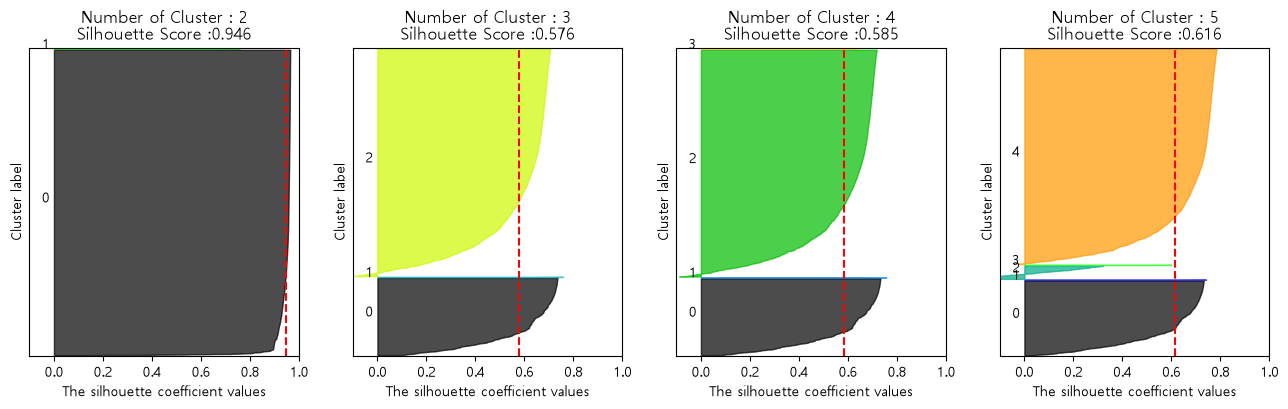

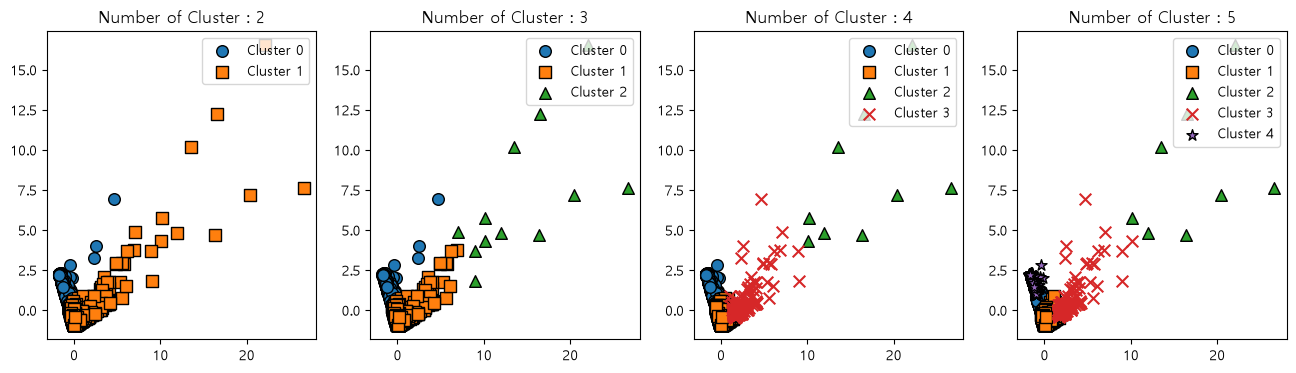

In [55]:
visualize_silhouette([2,3,4,5],X_features_scaled)
visualize_kmeans_plot_multi([2,3,4,5],X_features_scaled)


**실루엣 점수는 0.576으로 높은데 그림은 엉망이다.** 군집 하나가 거의 모든 점을 차지하고
나머지는 오른쪽 구석에 몇 개씩 떨어져 있다.

이건 **치우친 분포 때문에 극단적인 고객 몇 명이 따로 떨어져 나간 것**이다.
"대부분의 평범한 고객 한 덩어리 + 특이 고객 몇 명"으로 나뉜 셈인데,
세그먼테이션으로는 쓸모가 없다. **점수가 높아도 쓸 수 없는 군집화가 나올 수 있다.**


In [56]:
### Log 변환을 통해 데이터 변환
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score, silhouette_samples

# Recency, Frequecny, Monetary 컬럼에 np.log1p() 로 Log Transformation
cust_df['Recency_log'] = np.log1p(cust_df['Recency'])
cust_df['Frequency_log'] = np.log1p(cust_df['Frequency'])
cust_df['Monetary_log'] = np.log1p(cust_df['Monetary'])

# Log Transformation 데이터에 StandardScaler 적용
X_features = cust_df[['Recency_log','Frequency_log','Monetary_log']].values
X_features_scaled = StandardScaler().fit_transform(X_features)

kmeans = KMeans(n_clusters=3, random_state=0)
labels = kmeans.fit_predict(X_features_scaled)
cust_df['cluster_label'] = labels

print('실루엣 스코어는 : {0:.3f}'.format(silhouette_score(X_features_scaled,labels)))


실루엣 스코어는 : 0.303


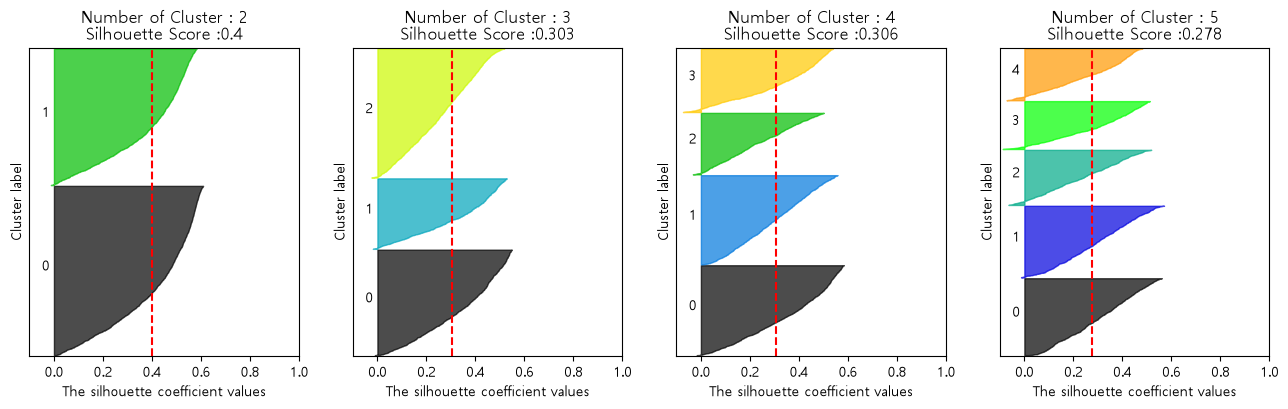

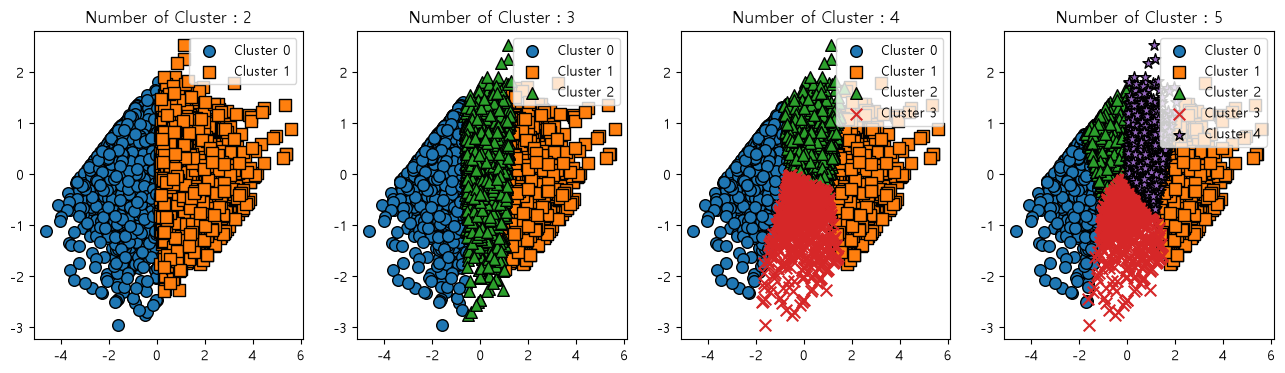

In [57]:
visualize_silhouette([2,3,4,5],X_features_scaled)
visualize_kmeans_plot_multi([2,3,4,5],X_features_scaled)


**실루엣 점수는 0.576에서 0.303으로 떨어졌는데 군집은 훨씬 쓸 만해졌다.**
세 덩어리가 고르게 나뉘고 크기도 비슷하다.

이 장면이 7장에서 제일 배울 점이다. **군집화는 지표를 올리는 작업이 아니다.**
회귀·분류는 RMSE나 정확도가 올라가면 좋아진 것이지만, 군집화에는 맞고 틀림이 없다.
**"이 결과로 무엇을 할 수 있는가"가 기준**이고, 실루엣은 참고값일 뿐이다.

로그 변환이 여기서도 효과를 냈다. 5장 타깃 변환, 미니 프로젝트(3)의 관객수에 이어 세 번째인데,
**목적이 매번 다르다** — 회귀에서는 선형성을 만들기 위해, 여기서는 **거리를 고르게 만들기 위해서**다.


## 7.7 정리

| 절 | 알고리즘 | 기준 | 군집 수 | 정해야 하는 값 | 잘하는 것 |
|---|---|---|---|---|---|
| 7.1 | **K-평균** | 중심까지의 **거리** | 지정 | `n_clusters` | 둥글고 크기 비슷한 군집. 빠르다 |
| 7.3 | **평균 이동** | **밀도**가 높은 쪽 | 자동 | `bandwidth` | 영상 처리. 느리다 |
| 7.4 | **GMM** | 정규분포 **확률** | 지정 | `n_components` | 길쭉한 타원 모양 |
| 7.5 | **DBSCAN** | **이웃의 밀집도** | 자동 | `eps`, `min_samples` | 복잡한 모양 + 노이즈 분리 |

**평가는 실루엣 계수**로 한다. −1~1이고 1에 가까울수록 좋지만, **평균만 보면 안 되고
군집들이 고르게 나뉘었는지를 함께 봐야 한다.**

7장을 관통하는 것은 **"데이터의 모양에 맞는 알고리즘이 따로 있다"**는 것이다.
- 길쭉한 데이터(7.4) — K-평균 ✗, GMM ✓
- 원 안의 원(7.5) — K-평균 ✗, GMM ✗, DBSCAN ✓
- 붓꽃(7.4) — K-평균보다 GMM이 나음

**어느 하나가 늘 낫지 않다.** 6장에서 PCA·LDA·SVD·NMF가 "무엇을 보존하는가"로 갈렸던 것처럼,
7장은 **"군집을 어떤 모양으로 보는가"**로 갈린다.


## 느낀 점

**정답이 없는 문제를 처음 제대로 다뤄 봤다.** 6장 차원 축소도 비지도였지만 결국 분류 정확도로
좋고 나쁨을 가렸다. 7.6 고객 세그먼테이션에는 비교할 것이 아무것도 없었다.
그런데도 로그 변환 전후를 비교할 수 있었던 건 **실루엣 점수가 아니라 그림을 봤기 때문**이다.
점수는 0.576에서 0.303으로 떨어졌는데 결과는 더 좋아졌다. **지표가 목적이 아닌 경우를 처음 만났다.**

**K-평균이 원 모양으로만 자른다는 걸 그림으로 보고서야 이해했다.** 중심까지의 거리로 배정한다는
설명은 7.1에서 읽었지만 그게 무슨 뜻인지는 와닿지 않았다. 7.4의 길쭉한 데이터에서 K-평균이
세 덩어리를 가로질러 자르는 그림, 7.5의 `make_circles`에서 위아래로 뎅강 자르는 그림을 보고
**"거리로 묶으면 군집은 반드시 원이 된다"**가 당연한 말로 들렸다.
알고리즘의 가정을 글로 외우는 것과 깨지는 장면을 보는 것은 다르다.

**군집 개수를 안 정해도 되는 건 공짜가 아니었다.** 평균 이동과 DBSCAN이 군집 수를 자동으로
정해 준다길래 K-평균보다 편한 줄 알았는데, 평균 이동은 `bandwidth` 0.8과 1의 차이로
군집이 6개에서 3개가 됐고 DBSCAN은 `eps`와 `min_samples`가 서로 반대로 작동했다.
**정해야 할 값이 사라진 게 아니라 다른 것으로 바뀐 것**이고, 오히려 감을 잡기 더 어려웠다.

**붓꽃은 데이터만 보면 두 덩어리였다.** 7.2 실루엣 분석에서 K=2가 가장 높게 나오고,
7.5 DBSCAN도 군집을 2개로 잡았다. 품종이 3개라는 걸 알고 있으니까 3을 고르는 것이지,
정답을 모르면 2를 고를 수밖에 없다. **군집화가 찾아 주는 구조와 우리가 알고 싶은 구조가
같다는 보장이 없다.** 미니 프로젝트(3)에서 "데이터에 없는 것은 모델이 만들 수 없다"고 정리했는데,
여기서는 **데이터에 있는 구조가 우리가 원하는 구조가 아닐 수도 있다**는 쪽이다.

**RFM이 인상적이었다.** 거래 54만 건을 고객 3,920명으로 접으면서 변수를 세 개만 남겼는데,
그 세 개가 "최근·자주·많이"라는 상식적인 축이다. 머신러닝 기법이 아니라 **도메인에서 나온 설계**이고,
군집화는 그 위에 얹힌 것뿐이다. week13에 읽은 주차수요 예측 수상작에서도 전처리의 절반이
"여러 행을 단지 하나로 합치는 일"이었다. **데이터를 어떤 단위로 볼 것인가를 정하는 것이
알고리즘을 고르는 것보다 앞선다.**
